# 每日太阳能发电：从 pandas 数据处理到分布分析

题目：绘制每日太阳能发电量的时间序列和直方图；去季节性后重画直方图，
描述分布，并思考如何使其更接近正态。

学习主线是：**明确“一天”和“合计”的含义 → 检查完整性 → 聚合 →
估计季节基准 → 比较分布 → 决定是否需要变换**。

本课先用透明的“月份均值法”做初步年度季节调整，最后提供 STL 进阶。
不预设数据一定要变成正态，也不以“成功取 log”为目标。

数据为之前使用的 `energy_dataset.csv`。需要 pandas、NumPy、Matplotlib、SciPy
和 IPython；进阶部分另需 statsmodels。原 CSV 不会被修改。

CSV 未注明单位。因此以下将合计标为“每日小时读数之和”。如果原数值是每小时
平均 MW，每个一小时区间乘以 1h 后再相加，结果为 MWh；如果本来就是每小时
MWh，则直接相加。确认元数据后再正式标注单位。


## 1. 明确时间与分析对象

一行是一个小时的记录。我们需要 `generation solar`，而不是日前太阳能预测。
用 UTC 检查真实时间是否连续；用文件中原有的当地日期定义“每天”。

`str.slice(0, 19)` 取出原来的年月日时分秒，供日历分组使用；它没有时区，
不能用于计算经过了多少小时。`.dt.normalize()` 将当地时间归到当天零点。
UTC 索引用来验证数据没有漏掉整行小时记录。


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy import stats
from IPython.display import display

raw = pd.read_csv('/Users/jiongwu/Downloads/archive/energy_dataset.csv')
raw['date'] = pd.to_datetime(raw['time'].str.slice(0, 19)).dt.normalize()
raw['time'] = pd.to_datetime(raw['time'], utc=True)
df = raw.set_index('time').sort_index()

expected_timeline = pd.date_range(df.index.min(), df.index.max(), freq='h')
assert df.index.equals(expected_timeline), '先检查重复时间、缺失小时或非整点记录。'

plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
print('小时行数：', len(df))
print('太阳能缺失小时读数：', df['generation solar'].isna().sum())
display(df[['date', 'generation solar']].head())


小时行数： 35064
太阳能缺失小时读数： 18


,date,generation solar
time,,
2014-12-31 23:00:00+00:00,2015-01-01,49.0
2015-01-01 00:00:00+00:00,2015-01-01,50.0
2015-01-01 01:00:00+00:00,2015-01-01,50.0
2015-01-01 02:00:00+00:00,2015-01-01,50.0
2015-01-01 03:00:00+00:00,2015-01-01,42.0


## 2. 小时汇总为每日，并检查完整性

`groupby('date')` 把同一天的行放在一起。`.sum(min_count=1)` 表示至少有一个
非缺失值才返回合计，避免“全缺失的一天被求和为零”。但它仍会返回部分日合计。

因此还要比较 `.count()`（有效数值数量）与 `.size()`（该组总行数）。上一步已
证明小时轴完整，所以该日总行数可作为这份文件中应有的小时数。它可能是 23、
24 或 25，不能一律要求 24。缺读数的日合计先记作 NaN，避免低估。


In [2]:
grouped = df.groupby('date')['generation solar']
daily_check = pd.DataFrame({
    'sum_available': grouped.sum(min_count=1),
    'valid_hours': grouped.count(),
    'expected_hours': grouped.size(),
})
daily_check['complete'] = daily_check['valid_hours'].eq(daily_check['expected_hours'])

daily = daily_check['sum_available'].where(daily_check['complete']).asfreq('D')
daily.name = 'daily_solar'

print('日历天数：', len(daily))
print('完整日：', daily.notna().sum())
print('不完整日：', daily.isna().sum())
print('每天应有小时数的分布：')
display(daily_check['expected_hours'].value_counts().sort_index().to_frame('days'))
print('不完整的日期：')
display(daily_check.loc[~daily_check['complete']])


日历天数： 1461
完整日： 1450
不完整日： 11
每天应有小时数的分布：


,days
expected_hours,
23,4
24,1453
25,4


不完整的日期：


,sum_available,valid_hours,expected_hours,complete
date,,,,
2015-01-05,18461.0,17,24,False
2015-01-19,16471.0,22,24,False
2015-01-27,27542.0,23,24,False
2015-01-28,26540.0,23,24,False
2015-04-16,21163.0,23,24,False
2015-04-23,47105.0,23,24,False
2015-06-15,25942.0,23,24,False
2015-10-02,14595.0,23,24,False
2015-12-02,17494.0,23,24,False


实际结果：1461 个当地日期中有 1450 个完整日，11 天太阳能读数不完整。
保留这 1461 个日期的位置；画直方图时才 `.dropna()`，避免改变时间序列的间隔。
本题主分析保留可疑零读数并明确标记，后面单独检查排除它们的影响。


## 3. 建立容易理解的年度季节基准

每日太阳能合计主要关心“年”的季节性。入门方法：把所有年份的 1 月放在一起，
估计 1 月的平均每日合计；对 2 月到 12 月重复，然后减去对应月份的平均值。

记日合计为 $Y_t$，则本方法构造 $A_t = Y_t - \widehat\mu_{month(t)}$。
$A_t$ 表示当天比“同月份的平均日”高或低多少，因此可以是负数。

`.mean()` 只返回 12 个值。`.transform('mean')` 会把各组均值放回每一天的位置，
返回与原序列一样长、索引一致的结果，便于逐行相减。


In [3]:
month_mean = daily.groupby(daily.index.month).mean()
seasonal_baseline = daily.groupby(daily.index.month).transform('mean')
adjusted = daily - seasonal_baseline
adjusted.name = 'monthly_centered'

display(month_mean.to_frame('mean_daily_total'))
display(pd.DataFrame({
    'daily_total': daily,
    'month_baseline': seasonal_baseline,
    'adjusted': adjusted,
}).head(8))


,mean_daily_total
date,
1,25789.625000
2,29443.628319
3,32558.951613
4,34923.262712
5,41618.435484
6,46448.495798
7,47847.147541
8,42215.354839
9,38289.141667


,daily_total,month_baseline,adjusted
date,,,
2015-01-01,27443.0,25789.625,1653.375
2015-01-02,30053.0,25789.625,4263.375
2015-01-03,26871.0,25789.625,1081.375
2015-01-04,57660.0,25789.625,31870.375
2015-01-05,NaN,25789.625,NaN
2015-01-06,54315.0,25789.625,28525.375
2015-01-07,55267.0,25789.625,29477.375
2015-01-08,55232.0,25789.625,29442.375


这是粗粒度的年度季节调整：只移除了稳定的“月份平均水平差异”，不能宣称所有
季节性都已消失。月内的平滑变化、天气波动、趋势和年际差异仍可能存在。
月均值中心化还会移除整体平均水平；若想保留原平均水平，可加回 `daily.mean()`，
这不会改变分布形状。描述性分析使用全样本估计基准；预测时应仅用训练集估计。


## 4. 同时看时间序列和分布

时间序列保留先后顺序，用于观察周期、异常和变化；直方图把时间顺序折叠掉，
用于观察集中程度、对称性、尾部和峰的形状。直方图的 `density=True` 允许叠加
使用相同样本均值与标准差的正态密度线，便于比较形状。参考线不是正态性证明。


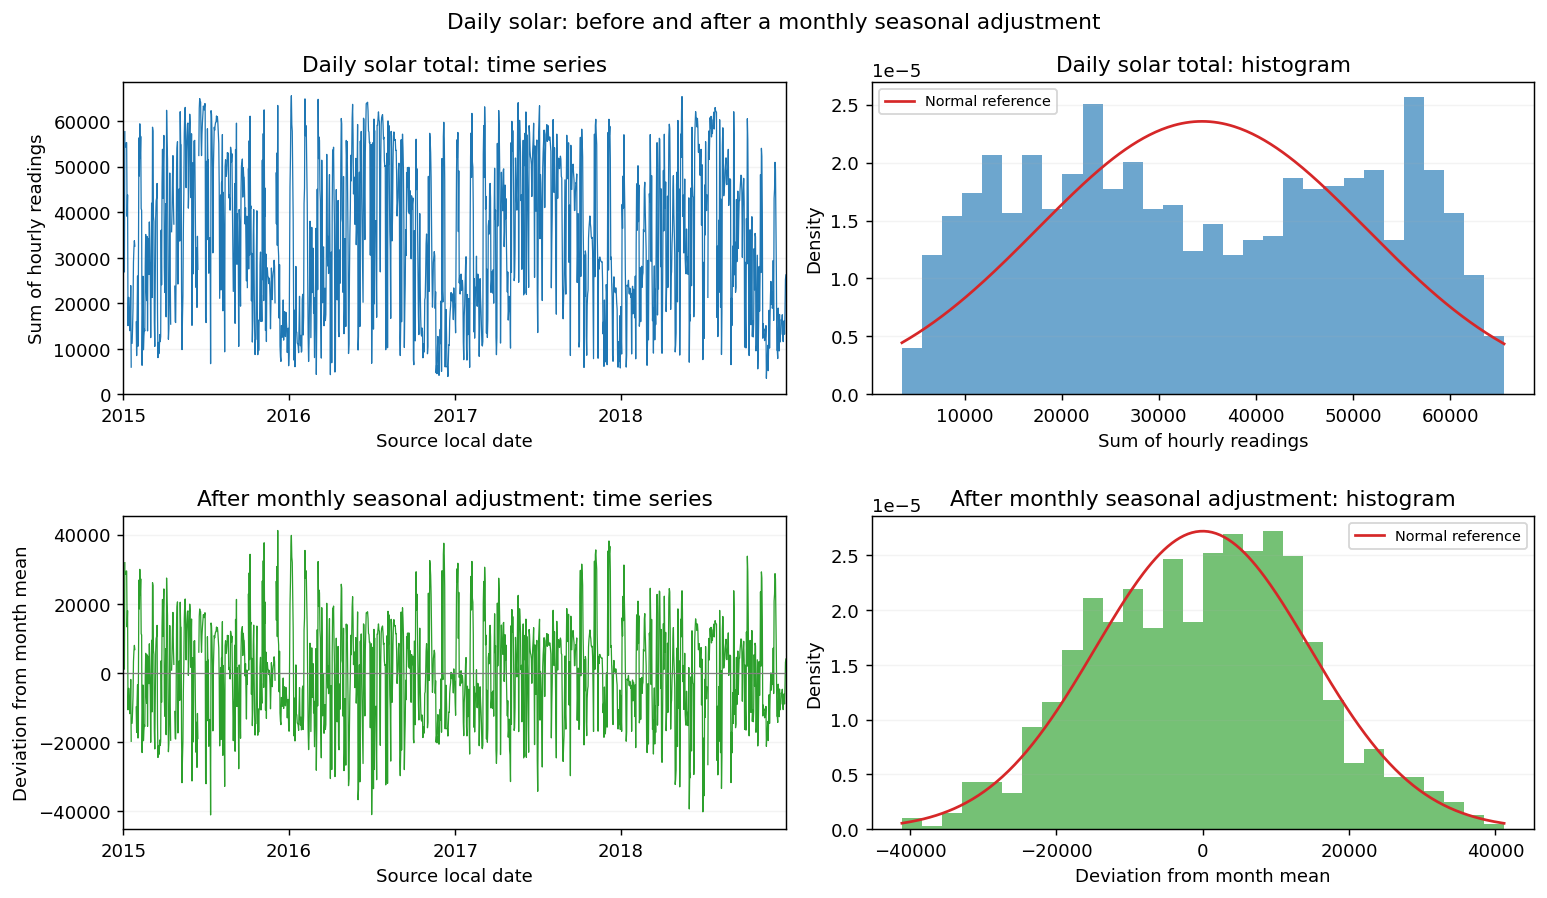

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for row, (series, label, color) in enumerate([
    (daily, 'Daily solar total', 'tab:blue'),
    (adjusted, 'After monthly seasonal adjustment', 'tab:green'),
]):
    axes[row, 0].plot(series.index, series, linewidth=0.7, color=color)
    axes[row, 0].set_title(label + ': time series')
    axes[row, 0].set_xlabel('Source local date')
    axes[row, 0].set_ylabel('Sum of hourly readings' if row == 0 else 'Deviation from month mean')
    axes[row, 0].xaxis.set_major_locator(mdates.YearLocator())
    axes[row, 0].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    axes[row, 0].set_xlim(series.index.min(), series.index.max())
    if row == 0:
        axes[row, 0].set_ylim(bottom=0)
    else:
        axes[row, 0].axhline(0, color='gray', linewidth=0.7)

    values = series.dropna()
    axes[row, 1].hist(values, bins=30, density=True, color=color, alpha=0.65)
    x = np.linspace(values.min(), values.max(), 300)
    axes[row, 1].plot(x, stats.norm.pdf(x, values.mean(), values.std()),
                      color='tab:red', label='Normal reference')
    axes[row, 1].set_title(label + ': histogram')
    axes[row, 1].set_xlabel('Sum of hourly readings' if row == 0 else 'Deviation from month mean')
    axes[row, 1].set_ylabel('Density')
    axes[row, 1].legend(fontsize=8)
    for ax in axes[row]:
        ax.grid(axis='y', alpha=0.15)
fig.suptitle('Daily solar: before and after a monthly seasonal adjustment')
fig.tight_layout()
plt.show()


## 5. 用证据描述分布，并尝试变换

偏度（skewness）接近 0 表示较对称；超额峰度（excess kurtosis）在正态分布中
为 0，负值表示相对正态更平、尾部更轻的形状。但单看这两个数不能证明正态。
正态 Q–Q 图将样本分位数与理论正态分位数比较，点越贴近参考线，形状越接近。

去季节后的数值包含负数，不能直接取 log 或做要求正值的 Box–Cox。
Yeo–Johnson 可以处理负数、零和正数。SciPy 在不指定 lambda 时估计变换参数。

另作一个有教学意义的对比：先对正的原始每日合计取 log，再在 log 尺度重新
去季节。不能把先后次序不同的操作当成一回事。


,n,skewness,excess_kurtosis
Original daily,1450.0,0.0314,-1.2678
Monthly adjusted,1450.0,0.0003,-0.3386
Adjusted then Yeo-Johnson,1450.0,0.0719,-0.3226
Log daily then adjusted,1450.0,-0.7793,0.5448


Yeo–Johnson lambda = 1.003537


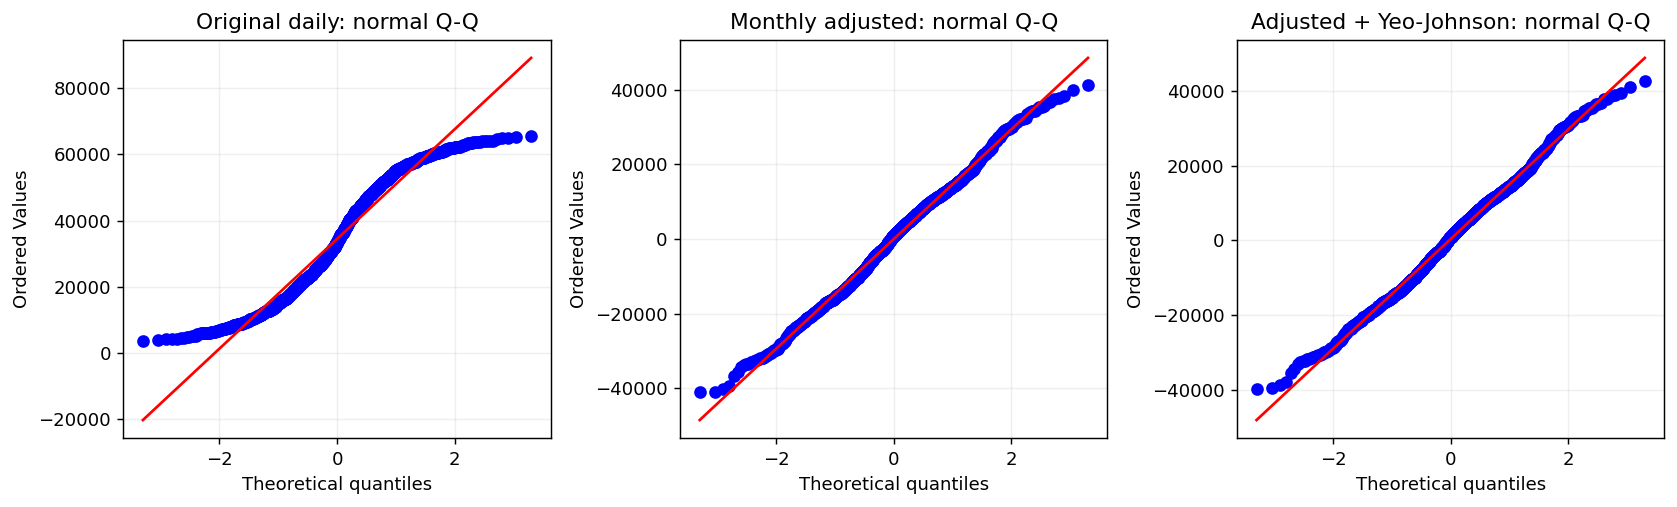

In [5]:
# Yeo–Johnson 返回 NumPy 数组；显式放回原来有效日期的索引。
valid_adjusted = adjusted.dropna()
transformed_values, fitted_lambda = stats.yeojohnson(valid_adjusted.to_numpy())
transformed = pd.Series(transformed_values, index=valid_adjusted.index, name='Yeo_Johnson')

# 本数据完整日合计均为正；先检查，再对原始合计取对数。
assert daily.dropna().gt(0).all(), '存在非正值，不能直接对原始日合计取 log。'
log_daily = np.log(daily)
log_adjusted = log_daily - log_daily.groupby(log_daily.index.month).transform('mean')

def distribution_summary(series):
    values = series.dropna()
    return pd.Series({
        'n': len(values),
        'skewness': values.skew(),
        'excess_kurtosis': values.kurt(),
    })

comparison = pd.DataFrame({
    'Original daily': distribution_summary(daily),
    'Monthly adjusted': distribution_summary(adjusted),
    'Adjusted then Yeo-Johnson': distribution_summary(transformed),
    'Log daily then adjusted': distribution_summary(log_adjusted),
}).T
display(comparison.round(4))
print(f'Yeo–Johnson lambda = {fitted_lambda:.6f}')

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, series, label in zip(
    axes,
    [daily, adjusted, transformed],
    ['Original daily', 'Monthly adjusted', 'Adjusted + Yeo-Johnson'],
):
    stats.probplot(series.dropna(), dist='norm', plot=ax)
    ax.set_title(label + ': normal Q-Q')
    ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()


**这份数据的实际结论：**原始每日合计偏度约 0.031，虽然较对称，但超额峰度
约 −1.268，形状明显不同于正态。月均值调整后偏度约 0.000，超额峰度约 −0.339，
Q–Q 图也更贴近直线，说明已经明显接近正态。

Yeo–Johnson 的 lambda 约 1.0035，接近不变换；改善不明显。先取 log 再调整的
偏度约 −0.779，反而更偏。因此合理答案是“去季节后已改善很多，没有充分理由
继续做强变换”，而不是为了完成题目而强行取对数。

这仍不等于数据严格服从正态，也不意味着时间上的观测互相独立。正态性和
自相关是不同问题。本课不把正态性检验的 p 值当作唯一判断标准。


## 6. 数据问题的敏感性检查：可疑零值

前面的审查发现有三个小时，13 个活跃来源中的 12 个同时为零。这里按同样的
“至少 80% 来源为零，且读数齐全”规则标注，并暂时排除涉及的整天重新计算。
这只是敏感性分析，不是认定这些零值一定错误，也不是为了让直方图更好看。
主分析原值保留；应结合源记录和上下文进一步核实。


In [6]:
generation = df.filter(regex=r'^generation ').drop(
    columns=['generation hydro pumped storage consumption']
)
active = (generation.notna() & generation.ne(0)).any()
recorded_sources = generation.loc[:, active]
suspicious_hour = (
    recorded_sources.notna().all(axis=1)
    & recorded_sources.eq(0).mean(axis=1).ge(0.80)
)
suspicious_dates = pd.DatetimeIndex(df.loc[suspicious_hour, 'date'].unique()).sort_values()
print('可疑小时数量：', int(suspicious_hour.sum()))
print('涉及当地日期：', suspicious_dates.strftime('%Y-%m-%d').tolist())

alternative = daily.copy()
alternative.loc[alternative.index.isin(suspicious_dates)] = np.nan
alternative_adjusted = alternative - alternative.groupby(alternative.index.month).transform('mean')
sensitivity = pd.DataFrame({
    'Main adjusted view': distribution_summary(adjusted),
    'Flagged days omitted': distribution_summary(alternative_adjusted),
}).T
display(sensitivity.round(4))


可疑小时数量： 3
涉及当地日期： ['2017-11-12', '2017-11-14']


,n,skewness,excess_kurtosis
Main adjusted view,1450.0,0.0003,-0.3386
Flagged days omitted,1448.0,-0.0006,-0.3409


## 7. 可选进阶：STL 年度分解

若题目要求时间序列分解，可使用 STL。每日太阳能应先考虑年度周期；
`period=365` 是年度周期的近似，而不是周周期。含闰年的日历年并非严格 365 天，
且仅有四年样本，结果需要谨慎解释。月份法不会因 `dayofyear` 在闰年后错位。

STL 拟合需要规则、无缺失的输入。这里保留日频网格，只为拟合季节项临时
插补内部最多连续两天的缺失，再用原始 `daily` 减去季节项。因此插补值不会
混入本课用于描述分布的真实完整日样本。缺失更长时应重新设计处理方法。

`daily - fit.seasonal` 只去季节性、保留趋势；`fit.resid` 同时去趋势和季节性，
不能把两者混称。下面的 STL 结果是一种模型估计，应与月份法比较，不作为真值。


,n,skewness,excess_kurtosis
Monthly adjusted,1450.0,0.0003,-0.3386
STL seasonal adjusted,1450.0,-0.1896,2.8580


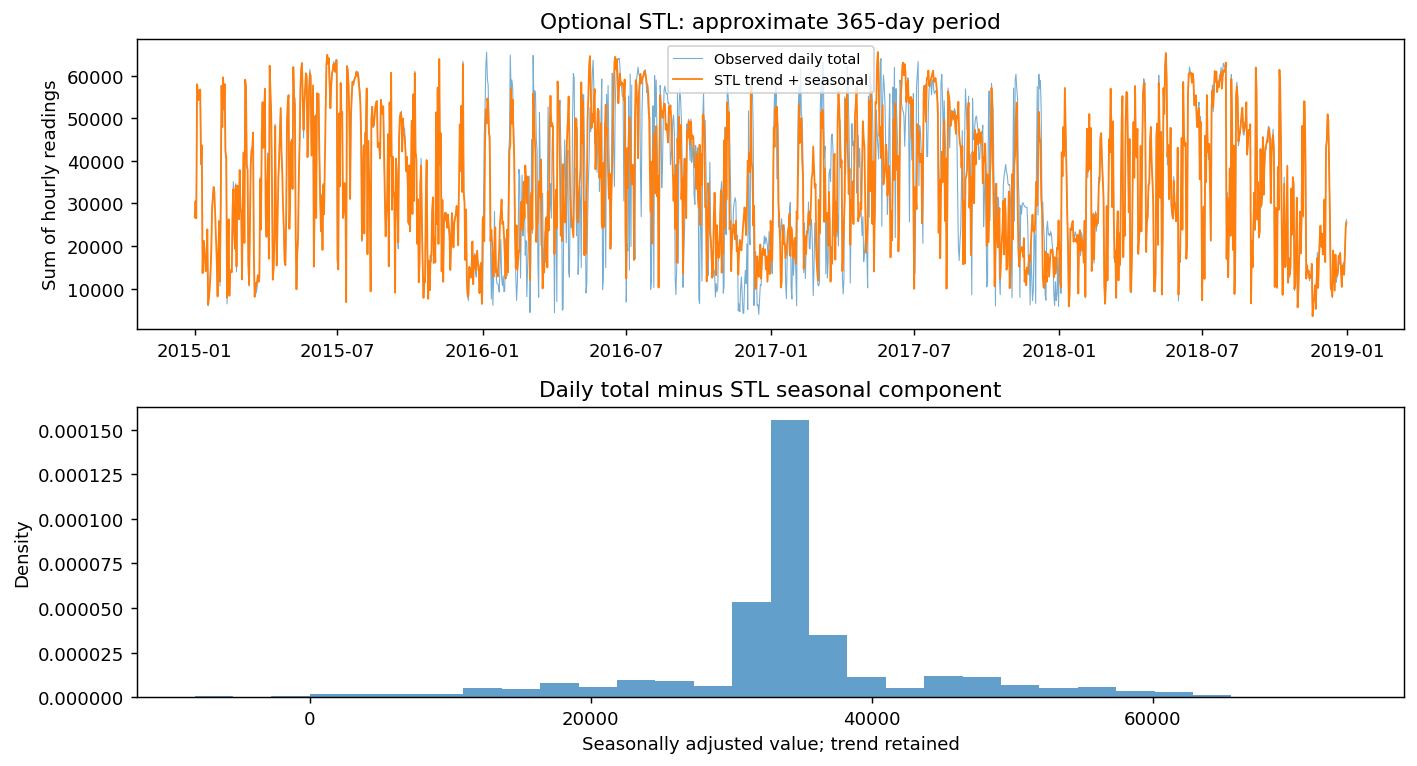

In [7]:
from statsmodels.tsa.seasonal import STL

fit_input = daily.interpolate(method='time', limit=2, limit_area='inside')
assert fit_input.notna().all(), '仍有缺失，先重新考虑插补策略。'
stl_fit = STL(fit_input, period=365, robust=True).fit()
stl_adjusted = daily - stl_fit.seasonal
assert stl_adjusted.isna().equals(daily.isna())

display(pd.DataFrame({
    'Monthly adjusted': distribution_summary(adjusted),
    'STL seasonal adjusted': distribution_summary(stl_adjusted),
}).T.round(4))

fig, axes = plt.subplots(2, 1, figsize=(11, 6))
axes[0].plot(daily.index, daily, linewidth=0.6, alpha=0.6, label='Observed daily total')
axes[0].plot(stl_fit.trend.index, stl_fit.trend + stl_fit.seasonal,
             linewidth=1, label='STL trend + seasonal')
axes[0].set_title('Optional STL: approximate 365-day period')
axes[0].set_ylabel('Sum of hourly readings')
axes[0].legend(fontsize=8)
axes[1].hist(stl_adjusted.dropna(), bins=30, density=True, alpha=0.7)
axes[1].set_title('Daily total minus STL seasonal component')
axes[1].set_xlabel('Seasonally adjusted value; trend retained')
axes[1].set_ylabel('Density')
fig.tight_layout()
plt.show()


本次 STL 季节调整结果的超额峰度约为 2.858，分布比月份法更尖，年度季节线也较
锯齿。仅四个年度周期下，灵活的年度剖面可能吸收偶然天气差异，属于需要检查的
线索，不能仅据此断言模型错误。插补、年度近似和边界估计也值得做敏感性分析。

**选择方法应先看季节性估计是否合理，而不是只选直方图最像正态的方法。**
本课以月份法为主，是因为它容易理解、假设透明；不是因为边际分布最好看就能
证明月份法最正确。进阶时还应检查调整后的日历模式、时间自相关和年际稳定性。


## 8. 怎样组织作答

1. 交代按原当地日期聚合，完整日筛选、单位和可疑零值处理。
2. 用时间序列描述周期和年际差异；用直方图描述原分布的对称性与形状。
3. 明确季节项如何估计、减掉了什么，以及方法的局限。
4. 用调整前后的直方图、Q–Q 图、偏度和超额峰度比较证据。
5. 说明尝试变换的结果，以及为什么选择保留较简单的处理。

可以这样概括：

“在小时轴检查后，按原当地日期求太阳能每日小时读数之和；11 个不完整日记为
缺失，得到 1450 个完整日。采用相同月份平均值作为初步年度季节基准。原始日
合计近似对称但分布较平，去季节后的分布更集中，Q–Q 图更贴近正态参考线，
超额峰度由约 −1.268 变为 −0.339。Yeo–Johnson 改善有限，log 后再调整反而
增加偏斜，因此没有必要为追求正态强行取对数。月份法是粗粒度调整，结论还应
结合异常值敏感性与更细季节模型检查。”

可自己尝试：将 30 个直方图分箱改为 20 和 40，观察结论是否稳定；分别对每年
作图，检查合并四年是否掩盖不同分布；比较月份法与 STL，但不要只挑最好看的图。

参考文档：
- [SciPy Yeo–Johnson](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.yeojohnson.html)
- [statsmodels STL](https://www.statsmodels.org/stable/generated/statsmodels.tsa.seasonal.STL.html)
